# 02 · Clasificación con árbol de decisión

**Responsable:** Ignacio González

**Pregunta:** ¿un día va a ser de alta demanda de viajes para una estación y un tipo de residuo?

**Datos:** `data/processed/datos_limpios.csv`, generado en `01_preparacion.ipynb`.

In [1]:
# Paso 1 · Librerías

import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn: la librería de aprendizaje automático.
# DecisionTreeClassifier es el árbol de decisión para clasificar;
# plot_tree lo dibuja (lo usamos al final para leer sus reglas)
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Métricas para evaluar el modelo (las usamos en la Etapa 4)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [2]:
# Paso 2 · Cargar los datos limpios

# parse_dates convierte "fecha" a tipo fecha al leer (en el CSV se guarda como texto)
df = pd.read_csv("../data/processed/datos_limpios.csv", parse_dates=["fecha"])

print(df.shape)
df.head()

(12330, 12)


,fecha,estacion,tipo,toneladas,viajes,anio,mes,dia_semana,feriado,sin_recoleccion,toneladas_sem_ant,viajes_sem_ant
0,2017-01-09,Norte,Basura,99.340123,30,2017,1,Lunes,0,0,70.523624,23
1,2017-01-09,Norte,Organicos,27.591310,7,2017,1,Lunes,0,0,23.750000,7
2,2017-01-09,Sur,Basura,325.610668,99,2017,1,Lunes,0,0,364.491521,111
3,2017-01-09,Sur,Organicos,211.350862,49,2017,1,Lunes,0,0,233.762208,48
4,2017-01-09,Sur,Reciclables,402.682309,85,2017,1,Lunes,0,0,402.273225,93


In [3]:
# Paso 3 · Variables de entrada

# Qué hacemos: definir qué columnas puede usar el modelo para predecir.

# Por qué: es acá donde se aplica la regla contra la fuga de información.
# Si se escribe la lista explícitamente, queda claro qué se usa y qué no,
# y nadie puede usar 'viajes' por error.

# Lista explícita de entradas permitidas.
# NO están 'viajes' ni 'toneladas' del mismo día: 'viajes' define la categoría
# que queremos predecir, y 'toneladas' está casi perfectamente relacionada con ella
# (correlación de 0,95). Usarlas sería darle la respuesta al modelo.
entradas = [
    "estacion", "tipo", "dia_semana",             # categóricas (texto)
    "anio", "mes", "feriado", "sin_recoleccion",  # de calendario (números)
    "toneladas_sem_ant", "viajes_sem_ant",        # semana anterior: ya ocurrieron, son válidas
]

df[entradas].head()

,estacion,tipo,dia_semana,anio,mes,feriado,sin_recoleccion,toneladas_sem_ant,viajes_sem_ant
0,Norte,Basura,Lunes,2017,1,0,0,70.523624,23
1,Norte,Organicos,Lunes,2017,1,0,0,23.750000,7
2,Sur,Basura,Lunes,2017,1,0,0,364.491521,111
3,Sur,Organicos,Lunes,2017,1,0,0,233.762208,48
4,Sur,Reciclables,Lunes,2017,1,0,0,402.273225,93


**Variables de entrada:** estación, tipo de residuo, día de la semana, año, mes, feriado, día sin recolección (`sin_recoleccion`) y los valores de la semana anterior.

Se excluyen `viajes` y `toneladas` del mismo día porque revelarían la respuesta: la categoría se construye con los viajes, y las toneladas tienen una correlación de 0,95 con ellos.

In [4]:
# Paso 4 · Codificación one-hot

# Qué hacemos: transformar las columnas de texto (estación, tipo, día) en columnas de 0 y 1.

# Por qué: scikit-learn solo trabaja con números.
# No podemos reemplazar “Norte” por 1 y “Sur” por 2, porque el modelo interpretaría que Sur es “más” que Norte, y eso no significa nada.
# La solución se llama codificación one-hot: una columna por cada valor posible, con 1 si la fila tiene ese valor y 0 si no.

# get_dummies crea una columna de 0 y 1 por cada valor de las columnas indicadas.
# Las columnas numéricas (anio, mes, feriado, sin_recoleccion, semana anterior) quedan como están.
# dtype=int hace que los valores sean 0 y 1 (si no, serían True y False)
X = pd.get_dummies(
    df[entradas],
    columns=["estacion", "tipo", "dia_semana"],
    dtype=int,
)

print(X.shape)
print(X.columns.tolist())
X.head()

(12330, 16)
['anio', 'mes', 'feriado', 'sin_recoleccion', 'toneladas_sem_ant', 'viajes_sem_ant', 'estacion_Norte', 'estacion_Sur', 'tipo_Basura', 'tipo_Organicos', 'tipo_Reciclables', 'dia_semana_Jueves', 'dia_semana_Lunes', 'dia_semana_Martes', 'dia_semana_Miercoles', 'dia_semana_Viernes']


,anio,mes,feriado,sin_recoleccion,toneladas_sem_ant,viajes_sem_ant,estacion_Norte,estacion_Sur,tipo_Basura,tipo_Organicos,tipo_Reciclables,dia_semana_Jueves,dia_semana_Lunes,dia_semana_Martes,dia_semana_Miercoles,dia_semana_Viernes
0,2017,1,0,0,70.523624,23,1,0,1,0,0,0,1,0,0,0
1,2017,1,0,0,23.750000,7,1,0,0,1,0,0,1,0,0,0
2,2017,1,0,0,364.491521,111,0,1,1,0,0,0,1,0,0,0
3,2017,1,0,0,233.762208,48,0,1,0,1,0,0,1,0,0,0
4,2017,1,0,0,402.273225,93,0,1,0,0,1,0,1,0,0,0


**Codificación one-hot:** las variables categóricas se transformaron en columnas de 0 y 1, una por cada valor posible. No se usaron números consecutivos (Norte = 1, Sur = 2) porque el modelo interpretaría un orden que no existe.

| `estacion` | → | `estacion_Norte` | `estacion_Sur` |
| --- | --- | --- | --- |
| Norte | | 1 | 0 |
| Sur | | 0 | 1 |

Las 9 variables de entrada se convierten en 16 columnas: 6 numéricas, 2 de estación, 3 de tipo de residuo y 5 de día de la semana.

In [5]:
# Paso 5 · División en entrenamiento y prueba

# Qué hacemos: separar los datos con los que el árbol aprende de los datos con los que lo evaluamos.

# Por qué por fecha y no al azar: queremos predecir días futuros. Si mezcláramos al azar,
# el modelo aprendería con días de 2026 y se evaluaría con días de 2020: estaría "viendo
# el futuro" y las métricas mentirían.

# Fecha de corte acordada con Lázaro (la misma en los dos notebooks).
# Todo lo anterior entrena; todo lo posterior evalúa.
FECHA_CORTE = "2024-12-01"

# Máscara: True en las filas de entrenamiento, False en las de prueba.
# Se calcula una sola vez y se usa para separar todo lo demás,
# así X, y y df quedan siempre alineados fila por fila
es_entrenamiento = df["fecha"] < FECHA_CORTE

print("Entrenamiento:", es_entrenamiento.sum(), "filas,",
      df.loc[es_entrenamiento, "fecha"].min().date(), "a", df.loc[es_entrenamiento, "fecha"].max().date())
print("Prueba:       ", (~es_entrenamiento).sum(), "filas,",
      df.loc[~es_entrenamiento, "fecha"].min().date(), "a", df.loc[~es_entrenamiento, "fecha"].max().date())
print(f"Proporción de prueba: {(~es_entrenamiento).mean():.1%}")

Entrenamiento: 10072 filas, 2017-01-09 a 2024-11-29
Prueba:        2258 filas, 2024-12-02 a 2026-09-04
Proporción de prueba: 18.3%


**División:** se entrena con los días anteriores al 1/12/2024 y se evalúa con los posteriores, respetando el orden temporal, porque el objetivo es predecir días futuros. Es la misma fecha de corte que usa el modelo de regresión.

Se usa una máscara (`es_entrenamiento`) en lugar de dos tablas separadas: con la misma máscara se separan después las entradas (`X`) y la respuesta (`y`), así no pueden quedar desalineadas.

In [6]:
# Paso 6 · Categoría de alta demanda

# Qué hacemos: marcar cada día con 1 (alta demanda) o 0 (normal), según si sus viajes
# superan la mediana de su estación y tipo de residuo.

# Por qué un umbral por estación y tipo: la estación Sur recibe varias veces más viajes que la Norte.
# Con un umbral único, la Sur sería siempre "alta" y la Norte siempre "normal".
# Por qué solo con entrenamiento: si usáramos todos los datos, el umbral contendría
# información del período de prueba (sería "mirar el futuro").

# Mediana de viajes por estación y tipo, calculada SOLO con entrenamiento
umbrales = (df[es_entrenamiento]
            .groupby(["estacion", "tipo"])["viajes"]
            .median()
            .rename("umbral_viajes"))
print(umbrales)

# join pega a cada fila el umbral de su estación y tipo,
# sin cambiar el orden ni la numeración de las filas
df = df.join(umbrales, on=["estacion", "tipo"])

# 1 si los viajes del día superan el umbral, 0 si no
df["alta_demanda"] = (df["viajes"] > df["umbral_viajes"]).astype(int)

# Separamos entradas (X) y respuesta (y) con la misma máscara del Paso 5.
# El árbol nunca ve df: recibe X (sin viajes ni toneladas del día) e y
X_ent, X_pru = X[es_entrenamiento], X[~es_entrenamiento]
y_ent, y_pru = df.loc[es_entrenamiento, "alta_demanda"], df.loc[~es_entrenamiento, "alta_demanda"]

print("\nX entrenamiento:", X_ent.shape, "| X prueba:", X_pru.shape)

estacion  tipo       
Norte     Basura         26.0
          Organicos       6.0
Sur       Basura         85.0
          Organicos      52.0
          Reciclables    86.0
Name: umbral_viajes, dtype: float64

X entrenamiento: (10072, 16) | X prueba: (2258, 16)


**Categoría:** un día es de **alta demanda** si sus viajes superan la mediana de su estación y tipo de residuo, calculada solo con los datos de entrenamiento. Se usa un umbral por combinación porque cada una tiene otra escala (la estación Sur recibe varias veces más viajes que la Norte), y la mediana deja aproximadamente la mitad de los días de entrenamiento en cada categoría.

La categoría se construye en `df`, que tiene los viajes del día, pero el árbol solo recibe `X`, que no los incluye.

              Entrenamiento  Prueba
alta_demanda                       
Normal                 5331    1018
Alta demanda           4741    1240


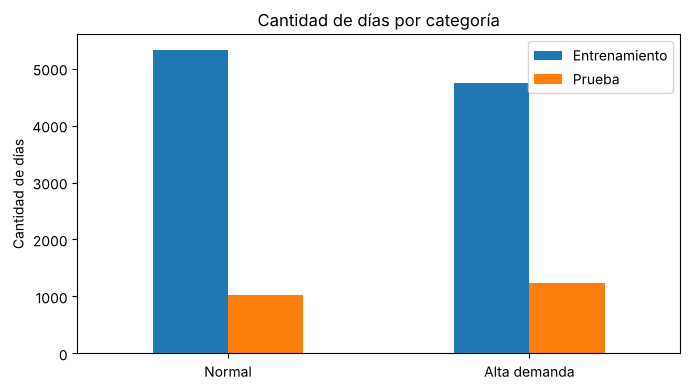

In [7]:
# Paso 7 · Casos por categoría

# Qué hacemos: contar cuántos días hay de cada categoría en entrenamiento y en prueba.
# Por qué: si una categoría tuviera muchos más casos que la otra, el modelo podría
# "acertar" casi siempre diciendo la mayoritaria sin aprender nada.

casos = pd.DataFrame({
    "Entrenamiento": y_ent.value_counts(),
    "Prueba": y_pru.value_counts(),
}).rename(index={0: "Normal", 1: "Alta demanda"})
print(casos)

# Gráfico de barras: una barra por categoría y conjunto
ax = casos.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title("Cantidad de días por categoría")
ax.set_xlabel("")
ax.set_ylabel("Cantidad de días")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [8]:
# Proporción de días de alta demanda en prueba, por estación y tipo
(df[~es_entrenamiento]
 .groupby(["estacion", "tipo"])["alta_demanda"]
 .mean()
 .round(3)
 .rename("Proporción de alta demanda en prueba"))

estacion  tipo       
Norte     Basura         0.491
          Organicos      0.444
Sur       Basura         0.811
          Organicos      0.413
          Reciclables    0.581
Name: Proporción de alta demanda en prueba, dtype: float64

**Casos por categoría:**

| | Entrenamiento | Prueba |
| --- | --- | --- |
| Normal | 5.331 (53 %) | 1.018 (45 %) |
| Alta demanda | 4.741 (47 %) | 1.240 (55 %) |

En entrenamiento las clases quedan casi balanceadas por construcción. No es exactamente 50/50 porque muchos días tienen exactamente la cantidad de viajes de la mediana, y como la regla es **superar** la mediana, cuentan como normales.

En prueba la proporción se invierte: hay más días de alta demanda. El aumento se concentra en la basura de la estación Sur (81 % de días altos en prueba), porque los viajes crecieron con los años y el umbral quedó fijado en el período de entrenamiento. Es una limitación que hay que tener en cuenta al evaluar el modelo.